# I.  Project Overview

<center><img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/preview.jpg?raw=1" width="700"></center>

In this project, we'll build a neural network classifier that determines: **MUFFIN... or CHIHUAHUA!**

This is what we'll cover in the tutorial:
#### 1) Build the neural network
#### 2) Load the data
#### 3) Train the model on the data
#### 4) Visualize the results

### Remember: This is an INTERACTIVE Notebook!
You should run and play with the code as you go to see how it works. Select a cell and **press shift-enter to execute code.**

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/jupyter_animated.gif?raw=1" width="700">

# II.  Deep Learning Tutorial

Let's get to the fun stuff!



<center><img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/Pytorch_logo.png?raw=1" width="700"></center>

**Generic Python imports** (select the below cell and press shift-enter to execute it)

In [ ]:
import matplotlib.pyplot as plt  # graphical library, to plot images
# special Jupyter notebook command to show plots inline instead of in a new window
%matplotlib inline

**Deep learning imports**

In [ ]:
import torch                                            # PyTorch deep learning framework
from torchvision import datasets, models, transforms    # extension to PyTorch for dataset management
import torch.nn as nn                                   # neural networks module of PyTorch, to let us define neural network layers
from torch.nn import functional as F                    # special functions
import torch.optim as optim                             # optimizers

## (1) Build our Neural Network

Recall from the lesson that a neural network generally looks like this. Input is on the left, output is on the right. The number of output neurons correspond to the number of classes.

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/what_is_nn_slide.jpg?raw=1" width="700">

So let's define a similar architecture for our 2-class muffin-vs-chihuahua classifier:

In [ ]:
#define image height and width
input_height = 224
input_width = 224

# Extends PyTorch's neural network baseclass
class MySkynet(nn.Module):
    """
    A very basic neural network.
    """
    def __init__(self, input_dim=(3, input_height, input_width)):
        """
        Constructs a neural network.

        input_dim: a tuple that represents "channel x height x width" dimensions of the input
        """
        super().__init__()

        # Calculates the total number of input values in one RGB image
        num_in_features = input_dim[0] * input_dim[1] * input_dim[2]

        # First layer receives all flattened image pixels
        self.layer_0 = nn.Linear(num_in_features, 128)

        # Hidden layers gradually reduce the number of features
        self.layer_1 = nn.Linear(128, 64)
        self.layer_2 = nn.Linear(64, 32)

        # Final layer produces two outputs: Chihuahua or muffin
        self.layer_3 = nn.Linear(32, 2)

    def forward(self, x):
        """
        Define the forward pass through our network.
        """

        # Gets the number of images in the current batch
        batch_size = x.shape[0]

        # Flattens each image into one long vector
        x = x.view(batch_size, -1)

        # Passes the data through each layer using ReLU activation
        x = F.relu(self.layer_0(x))
        x = F.relu(self.layer_1(x))
        x = F.relu(self.layer_2(x))
        x = F.relu(self.layer_3(x))

        # Converts the final outputs into class probabilities
        x = F.softmax(x, dim=1)

        return x

Now that we've defined the network above, let's initialize it. If available, we'll place the network on the GPU; if not, it goes on the CPU.

In [ ]:
# cuda:0 means the first CUDA-capable GPU found
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Creates our neural network and moves it to the selected device
model = MySkynet().to(device)

# Displays the model structure
model

MySkynet(
  (layer_0): Linear(in_features=150528, out_features=128, bias=True)
  (layer_1): Linear(in_features=128, out_features=64, bias=True)
  (layer_2): Linear(in_features=64, out_features=32, bias=True)
  (layer_3): Linear(in_features=32, out_features=2, bias=True)
)

Essentially, our network looks like this:
<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/architecture.png?raw=1" width="600">

## (2) Data and Data Loading

### Separate "train" and "test" datasets

Recall from the below slide, we should make two separate datasets to train and test our model. That way, we know our model learns more than rote memorization.

<center><img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/when_is_your_model_ready_slide.jpg?raw=1" width="600"></center>

### Inspect our data
Let's look in our data folder to see what's there. As you can see, the folder is **split into "train" for training**, and **"validation" for testing** (to validate our model).

In [ ]:
# Download the workshop files and dataset if they are not already in Colab
import os

if not os.path.exists("/content/workshop-chihuahua-vs-muffin"):
    !git clone https://github.com/patitimoner/workshop-chihuahua-vs-muffin.git

# Move into the workshop folder so paths like "data/train" work correctly
%cd /content/workshop-chihuahua-vs-muffin

/content/workshop-chihuahua-vs-muffin


In [ ]:
import os  # interact with the os. in our case, we want to view the file system

print("Data contents:", os.listdir("data"))
print("Train contents:", os.listdir("data/train"))
print("Validation contents:", os.listdir("data/validation"))

Data contents: ['train', 'validation']
Train contents: ['chihuahua', 'muffin']
Validation contents: ['chihuahua', 'muffin']


Let's also look at some of the images:

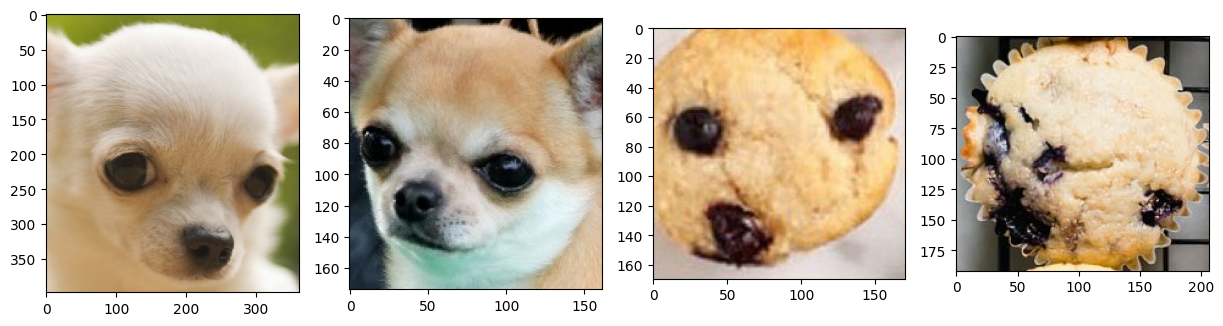

In [ ]:
from PIL import Image  # import our image opening tool

_, ax = plt.subplots(1, 4, figsize=(15,60))  # to show 4 images side by side, make a "1 row x 4 column" axes
ax[0].imshow(Image.open("data/train/chihuahua/4.jpg"))  # show the chihuahua in the first column
ax[1].imshow(Image.open("data/train/chihuahua/5.jpg"))  # show the chihuahua in the second column
ax[2].imshow(Image.open("data/train/muffin/131.jpg"))   # show the muffin in the third column
ax[3].imshow(Image.open("data/train/muffin/107.jpg"))   # show the muffin in the fourth column


If you look in the data folder on your computer, there are 120 train images and 30 validation. So our data is split like this:

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/folders.png?raw=1" width="600">

### Load our data

That's great that we have data! But we have to load all the images and convert them into a form that our neural network understands. Specifically, PyTorch works with **Tensor** objects. (A tensor is just a multidimensional matrix, i.e. an N-d array.)

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/image_to_tensor.jpg?raw=1" width="550">


**To easily convert our image data into tensors, we use the help of a "dataloader."** The dataloader packages data into convenient boxes for our model to use. You can think of it like one person passing boxes (tensors) to another.
<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/dataloader_box_analogy.jpg?raw=1" width="400">

**First, we define some "transforms" to convert images to tensors.** We must do so for both our train and validation datasets.

For more information about transforms, check out the link here: https://pytorch.org/docs/stable/torchvision/transforms.html

In [ ]:
normalize = transforms.Normalize(mean=[0.5, 0.5, 0.5],
                                 std=[0.5, 0.5, 0.5])

# transforms for our training data
train_transforms = transforms.Compose([
    # resize to resnet input size
    transforms.Resize((input_height,input_width)),
    # transform image to PyTorch tensor object
    transforms.ToTensor(),
    normalize
])

# these validation transforms are exactly the same as our train transforms
validation_transforms = transforms.Compose([
    transforms.Resize((input_height,input_width)),
    transforms.ToTensor(),
    normalize
])

print("Train transforms:", train_transforms)

Train transforms: Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


**Second, we create the datasets, by passing the transforms into the ImageFolder constructor.**

These just represent the folders that hold the images.

In [ ]:
# Apply the correct preprocessing transforms to each dataset
image_datasets = {
    'train':
        datasets.ImageFolder('data/train', train_transforms),
    'validation':
        datasets.ImageFolder('data/validation', validation_transforms)
}

# Display information about both datasets
print("==Train Dataset==\n", image_datasets["train"])
print()
print("==Validation Dataset==\n", image_datasets["validation"])

==Train Dataset==
 Dataset ImageFolder
    Number of datapoints: 120
    Root location: data/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )

==Validation Dataset==
 Dataset ImageFolder
    Number of datapoints: 30
    Root location: data/validation
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
           )


**And finally, form dataloaders from the datasets:**

In [ ]:
# Define batch size: number of images loaded at one time
dataloaders = {
    'train':
        torch.utils.data.DataLoader(
            image_datasets['train'],
            batch_size=8,      # Load 8 training images per batch
            shuffle=True,      # Shuffle training images each epoch
            num_workers=4),
    'validation':
        torch.utils.data.DataLoader(
            image_datasets['validation'],
            batch_size=8,      # Load 8 validation images per batch
            shuffle=False,     # Keep validation data in the same order
            num_workers=4)
}

# Display both data loaders
print("Train loader:", dataloaders["train"])
print("Validation loader:", dataloaders["validation"])

Train loader: <torch.utils.data.dataloader.DataLoader object at 0x7dca4b9fdc50>
Validation loader: <torch.utils.data.dataloader.DataLoader object at 0x7dca4b9fd450>


We can see a dataloader outputs 2 things: a BIG tensor to represent an image, and a vector to represent the labels (0 or 1).

In [ ]:
next(iter(dataloaders["train"]))

[tensor([[[[-0.5137, -0.4980, -0.4510,  ...,  0.4980,  0.5059,  0.4980],
           [-0.4588, -0.3804, -0.3647,  ...,  0.5059,  0.4980,  0.5059],
           [-0.3882, -0.3255, -0.2941,  ...,  0.5216,  0.5059,  0.4980],
           ...,
           [ 0.8118,  0.7725,  0.7098,  ...,  0.0667,  0.1451,  0.1373],
           [ 0.7961,  0.7569,  0.7333,  ...,  0.0275,  0.1137,  0.1216],
           [ 0.7725,  0.7569,  0.7647,  ...,  0.0431,  0.1137,  0.1059]],
 
          [[-0.5922, -0.5765, -0.5294,  ...,  0.4824,  0.4980,  0.4980],
           [-0.5294, -0.4510, -0.4353,  ...,  0.4902,  0.4902,  0.5059],
           [-0.4510, -0.3804, -0.3490,  ...,  0.5137,  0.4980,  0.5059],
           ...,
           [ 0.8118,  0.7725,  0.7098,  ...,  0.0196,  0.0824,  0.0745],
           [ 0.7961,  0.7569,  0.7333,  ..., -0.0039,  0.0745,  0.0745],
           [ 0.7725,  0.7569,  0.7647,  ...,  0.0196,  0.0902,  0.0824]],
 
          [[-0.6549, -0.6235, -0.5529,  ...,  0.4667,  0.4824,  0.4745],
           [-

## (4) Train the model!

Hurray! We've built a neural network and have data to give it. Now we **repeatedly iterate over the data to train the model.**

Every time the network gets a new example, it looks something like this. Note the **forward pass** and the corresponding **backward pass**.

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/backpropagation.gif?raw=1" width="700">

### Define the train loop

We want the network to learn from every example in our training dataset. However, the best performance comes from more practice. Therefore, we **run through our dataset for multiple *epochs*.**

After each epoch, we'll check how our model performs on the validation set to monitor its progress.

In [ ]:
from tqdm import tnrange, tqdm_notebook # import progress bars to show train progress

def train_model(model, dataloaders, loss_function, optimizer, num_epochs):
    """
    Trains a model using the given loss function and optimizer, for a certain number of epochs.

    model: a PyTorch neural network
    loss_function: a mathematical function that compares predictions and labels to return an error
    num_epochs: the number of times to run through the full training dataset
    """
    # train for n epochs. an epoch is a full iteration through our dataset
    for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):
        # print a header
        print('Epoch {}/{}'.format(epoch+1, num_epochs))
        print('----------------')

        # first train over the dataset and update weights; at the end, calculate our validation performance
        for phase in ['train', 'validation']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            # keep track of the overall loss and accuracy for this batch
            running_loss = 0.0
            running_corrects = 0

            # iterate through the inputs and labels in our dataloader
            # (the tqdm_notebook part is to display a progress bar)
            for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):
                # move inputs and labels to appropriate device (GPU or CPU)
                inputs = inputs.to(device)
                labels = labels.to(device)

                # FORWARD PASS
                outputs = model(inputs)
                # compute the error of the model's predictions
                loss = loss_function(outputs, labels)

                if phase == 'train':
                    # BACKWARD PASS
                    optimizer.zero_grad()  # clear the previous gradients
                    loss.backward()        # backpropagate the current error gradients
                    optimizer.step()       # update the weights (i.e. do the learning)

                # track our accumulated loss
                running_loss += loss.item() * inputs.size(0)
                # track number of correct to compute accuracy
                _, preds = torch.max(outputs, 1)
                running_corrects += torch.sum(preds == labels.data)

            # print our progress
            epoch_loss = running_loss / len(image_datasets[phase])
            epoch_acc = running_corrects.double() / len(image_datasets[phase])
            print(f'{phase} error: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}')

        print()

### Loss function and optimizer

One last thing: we must define a function that gives feedback for how well the model performs. This is the **loss**, or "error" **function**, that compares model predictions to the true labels.

Once we calculate the error, we also need to define how the model should react to that feedback. **The optimizer determines how the network learns from feedback.**

In [ ]:
loss_function = nn.CrossEntropyLoss()              # the most common error function in deep learning
optimizer = optim.SGD(model.parameters(), lr=0.1)  # Stochastic Gradient Descent, with a learning rate of 0.1

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/gradient_descent.gif?raw=1" width="700">

### Run training

Let's put everything together and TRAIN OUR MODEL! =D

In [ ]:
train_model(model, dataloaders, loss_function, optimizer, num_epochs=3)

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6144, Accuracy: 0.7250


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.3791, Accuracy: 0.9417


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.5537, Accuracy: 0.7667



## Examine model performance

<img src="https://github.com/patitimoner/workshop-chihuahua-vs-muffin/blob/master/resources/question_mark.jpg?raw=1" width="200" >

**How do we examine our model's predictions? Let's visualize what the model thinks on the validation set.**

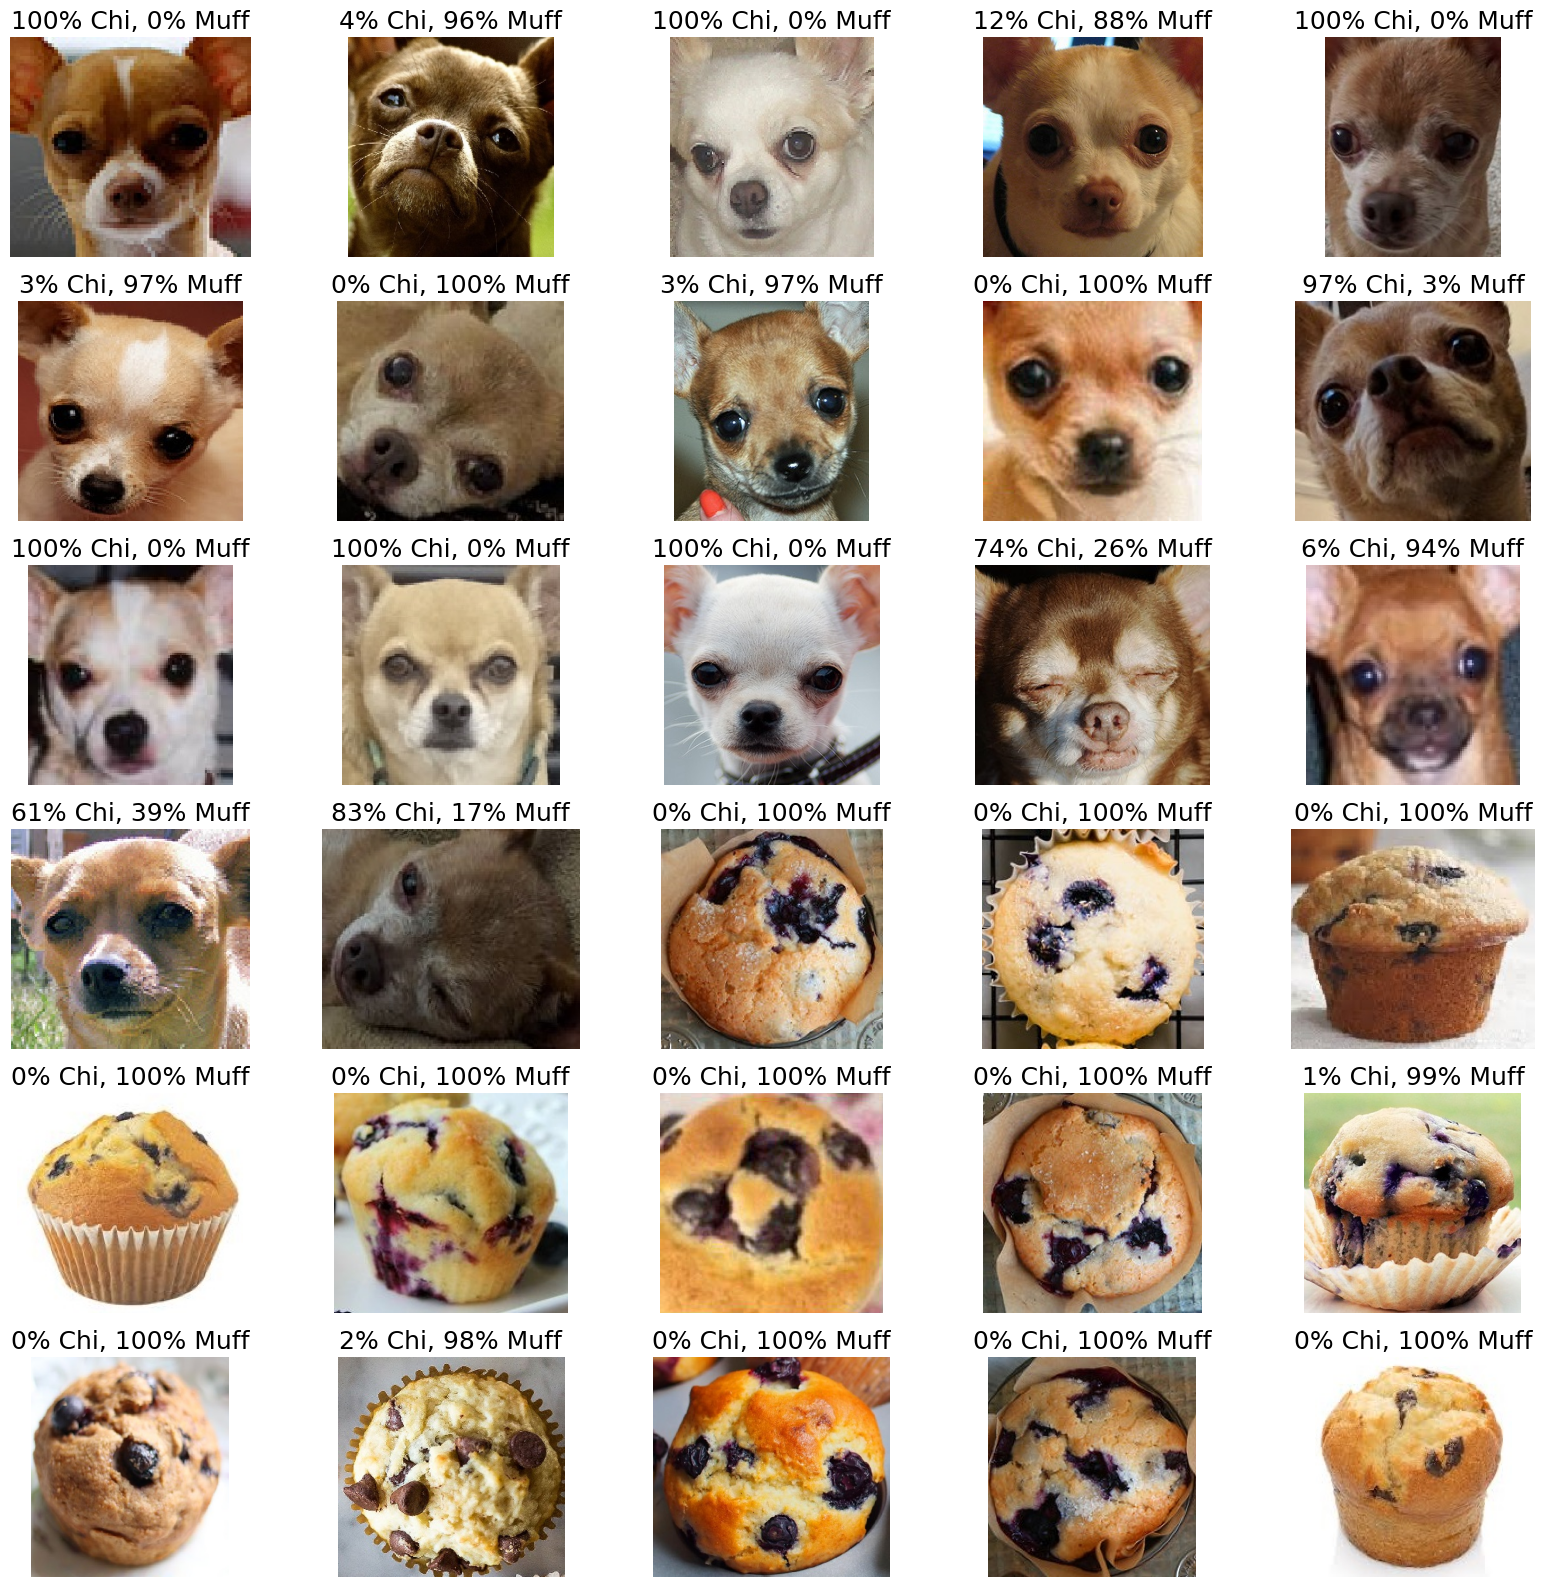

In [ ]:
from glob import glob
from math import floor

# get all the images from our validation sets
validation_img_paths = glob("data/validation/**/*.jpg", recursive=True)
images = [Image.open(img_path) for img_path in validation_img_paths]

# put all the images together to run through our model
validation_batch = torch.stack( [validation_transforms(img).to(device) for img in images])
pred_logits_tensor = model(validation_batch)
pred_probs = pred_logits_tensor.cpu().data.numpy()

# show the probabilities for each picture
fig, axs = plt.subplots(6, 5, figsize=(20, 20))
for i, img in enumerate(images):
    ax = axs[floor(i/5)][i % 5]
    ax.axis('off')
    ax.set_title("{:.0f}% Chi, {:.0f}% Muff".format(100*pred_probs[i,0], 100*pred_probs[i,1]), fontsize=18)
    ax.imshow(img)

**Consider:** How accurate was your model? How confident were its predictions? Does it make clear-cut decisions?

## Congratulations! You've successfully trained a neural network!

# III.  Can You Do Better?

Now that we've shown you how to train a neural network, can you improve the validation accuracy by tweaking the parameters? **We challenge you to reach 100% accuracy!**

Some parameters to play with:
- Number of epochs
- The learning rate "lr" parameter in the optimizer
- The type of optimizer (https://pytorch.org/docs/stable/optim.html)
- Number of layers and layer dimensions
- Image size
- Data augmentation transforms (https://pytorch.org/docs/stable/torchvision/transforms.html)

## Experiment Plan

To make the comparison clear, each experiment focuses on one of the parameters
suggested in the workshop. All experiments use the professor's original
`MySkynet` class, and none of the professor's original code is changed.

The six parameters tested are:

1. Number of epochs
2. Learning rate
3. Optimizer type
4. Number of layers and layer dimensions
5. Image size
6. Data augmentation transforms


In [ ]:
# Helper function used only to calculate final validation accuracy
def evaluate_validation(model, validation_loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in validation_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, predictions = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    return correct / total


# Evaluate the professor's original trained model as the baseline
baseline_accuracy = evaluate_validation(
    model,
    dataloaders['validation']
)

print(f"Baseline validation accuracy: {baseline_accuracy * 100:.2f}%")

Baseline validation accuracy: 76.67%


### Experiment 1: Number of Epochs

The original model trains for 3 epochs. In this experiment, I keep the original
`MySkynet`, SGD optimizer, learning rate of 0.1, image size, and transforms the
same, but increase training to 10 epochs.


In [ ]:
# Experiment 1: change only the number of epochs
experiment1_model = MySkynet().to(device)

experiment1_optimizer = optim.SGD(
    experiment1_model.parameters(),
    lr=0.1
)

experiment1_loss = nn.CrossEntropyLoss()

train_model(
    experiment1_model,
    dataloaders,
    experiment1_loss,
    experiment1_optimizer,
    num_epochs=10
)

experiment1_accuracy = evaluate_validation(
    experiment1_model,
    dataloaders['validation']
)

print(f"Experiment 1 validation accuracy: {experiment1_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/10 [00:00<?, ?epoch/s]

Epoch 1/10
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6540, Accuracy: 0.5583


... (34 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.3553, Accuracy: 0.9583


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.3831, Accuracy: 0.9333

Experiment 1 validation accuracy: 93.33%


### Experiment 2: Learning Rate

This experiment keeps `MySkynet`, SGD, 3 epochs, the original image size, and
the original transforms, but lowers the learning rate from 0.1 to 0.01.

In [ ]:
# Experiment 2: change the SGD learning rate
experiment2_model = MySkynet().to(device)

experiment2_optimizer = optim.SGD(
    experiment2_model.parameters(),
    lr=0.01
)

experiment2_loss = nn.CrossEntropyLoss()

train_model(
    experiment2_model,
    dataloaders,
    experiment2_loss,
    experiment2_optimizer,
    num_epochs=3
)

experiment2_accuracy = evaluate_validation(
    experiment2_model,
    dataloaders['validation']
)

print(f"Experiment 2 validation accuracy: {experiment2_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6811, Accuracy: 0.6333


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.5902, Accuracy: 0.9083


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.5701, Accuracy: 0.9000

Experiment 2 validation accuracy: 90.00%


### Experiment 3: Optimizer Type

This experiment uses a fresh `MySkynet` model and changes the optimizer from SGD
to Adam. Adam normally uses a smaller learning rate, so I use 0.001 while keeping
the original image size, transforms, and 3 training epochs.

In [ ]:
# Experiment 3: change the optimizer type to Adam
experiment3_model = MySkynet().to(device)

experiment3_optimizer = optim.Adam(
    experiment3_model.parameters(),
    lr=0.001
)

experiment3_loss = nn.CrossEntropyLoss()

train_model(
    experiment3_model,
    dataloaders,
    experiment3_loss,
    experiment3_optimizer,
    num_epochs=3
)

experiment3_accuracy = evaluate_validation(
    experiment3_model,
    dataloaders['validation']
)

print(f"Experiment 3 validation accuracy: {experiment3_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6070, Accuracy: 0.7333


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.4734, Accuracy: 0.8417


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.5404, Accuracy: 0.7667

Experiment 3 validation accuracy: 76.67%


### Experiment 4: Number of Layers and Layer Dimensions

This experiment still uses `MySkynet`, but changes only this model instance.
The original network has four Linear layers with dimensions
128 → 64 → 32 → 2. Here, I use five Linear layers and different dimensions:
96 → 64 → 48 → 32 → 2.

The professor's `MySkynet` class itself remains unchanged.

In [ ]:
# Experiment 4: create a fresh MySkynet instance
experiment4_model = MySkynet().to(device)

# Number of inputs for the original 224 x 224 RGB images
experiment4_num_inputs = 3 * input_height * input_width

# Change this instance's layer dimensions.
# layer_2 contains two Linear layers, increasing the total from 4 to 5.
experiment4_model.layer_0 = nn.Linear(
    experiment4_num_inputs, 96
).to(device)

experiment4_model.layer_1 = nn.Linear(
    96, 64
).to(device)

experiment4_model.layer_2 = nn.Sequential(
    nn.Linear(64, 48),
    nn.ReLU(),
    nn.Linear(48, 32)
).to(device)

experiment4_model.layer_3 = nn.Linear(
    32, 2
).to(device)

experiment4_optimizer = optim.SGD(
    experiment4_model.parameters(),
    lr=0.1
)

experiment4_loss = nn.CrossEntropyLoss()

train_model(
    experiment4_model,
    dataloaders,
    experiment4_loss,
    experiment4_optimizer,
    num_epochs=3
)

experiment4_accuracy = evaluate_validation(
    experiment4_model,
    dataloaders['validation']
)

print(f"Experiment 4 validation accuracy: {experiment4_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6811, Accuracy: 0.4750


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.5668, Accuracy: 0.8250


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.6219, Accuracy: 0.7333

Experiment 4 validation accuracy: 73.33%


### Experiment 5: Image Size

The original images are resized to 224 × 224. This experiment reduces the image
size to 128 × 128 while keeping the original transforms otherwise unchanged.
A fresh `MySkynet` is created with an input dimension that matches the smaller
images.

In [ ]:
# Experiment 5: use smaller 128 x 128 images
experiment5_size = 128

experiment5_train_transforms = transforms.Compose([
    transforms.Resize((experiment5_size, experiment5_size)),
    transforms.ToTensor(),
    normalize
])

experiment5_validation_transforms = transforms.Compose([
    transforms.Resize((experiment5_size, experiment5_size)),
    transforms.ToTensor(),
    normalize
])

experiment5_datasets = {
    'train': datasets.ImageFolder(
        'data/train',
        experiment5_train_transforms
    ),
    'validation': datasets.ImageFolder(
        'data/validation',
        experiment5_validation_transforms
    )
}

experiment5_dataloaders = {
    'train': torch.utils.data.DataLoader(
        experiment5_datasets['train'],
        batch_size=8,
        shuffle=True,
        num_workers=4
    ),
    'validation': torch.utils.data.DataLoader(
        experiment5_datasets['validation'],
        batch_size=8,
        shuffle=False,
        num_workers=4
    )
}

experiment5_model = MySkynet(
    input_dim=(3, experiment5_size, experiment5_size)
).to(device)

experiment5_optimizer = optim.SGD(
    experiment5_model.parameters(),
    lr=0.1
)

experiment5_loss = nn.CrossEntropyLoss()

train_model(
    experiment5_model,
    experiment5_dataloaders,
    experiment5_loss,
    experiment5_optimizer,
    num_epochs=3
)

experiment5_accuracy = evaluate_validation(
    experiment5_model,
    experiment5_dataloaders['validation']
)

print(f"Experiment 5 validation accuracy: {experiment5_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6608, Accuracy: 0.5917


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.4725, Accuracy: 0.8917


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.4442, Accuracy: 0.8667

Experiment 5 validation accuracy: 86.67%


### Experiment 6: Data Augmentation

This experiment returns to the original 224 × 224 image size and adds random
horizontal flips and small rotations to the training images. Validation images
are not augmented, so they remain a consistent comparison set.


In [ ]:
# Experiment 6: add data augmentation to training images
experiment6_train_transforms = transforms.Compose([
    transforms.Resize((input_height, input_width)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    normalize
])

# Validation images do not receive random augmentation
experiment6_validation_transforms = transforms.Compose([
    transforms.Resize((input_height, input_width)),
    transforms.ToTensor(),
    normalize
])

experiment6_datasets = {
    'train': datasets.ImageFolder(
        'data/train',
        experiment6_train_transforms
    ),
    'validation': datasets.ImageFolder(
        'data/validation',
        experiment6_validation_transforms
    )
}

experiment6_dataloaders = {
    'train': torch.utils.data.DataLoader(
        experiment6_datasets['train'],
        batch_size=8,
        shuffle=True,
        num_workers=4
    ),
    'validation': torch.utils.data.DataLoader(
        experiment6_datasets['validation'],
        batch_size=8,
        shuffle=False,
        num_workers=4
    )
}

experiment6_model = MySkynet().to(device)

experiment6_optimizer = optim.SGD(
    experiment6_model.parameters(),
    lr=0.1
)

experiment6_loss = nn.CrossEntropyLoss()

train_model(
    experiment6_model,
    experiment6_dataloaders,
    experiment6_loss,
    experiment6_optimizer,
    num_epochs=3
)

experiment6_accuracy = evaluate_validation(
    experiment6_model,
    experiment6_dataloaders['validation']
)

print(f"Experiment 6 validation accuracy: {experiment6_accuracy * 100:.2f}%")

/tmp/ipykernel_2119/963760017.py:12: TqdmDeprecationWarning: Please use `tqdm.notebook.trange` instead of `tqdm.tnrange`
  for epoch in tnrange(num_epochs, desc="Total progress", unit="epoch"):


Total progress:   0%|          | 0/3 [00:00<?, ?epoch/s]

Epoch 1/3
----------------


/tmp/ipykernel_2119/963760017.py:30: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for inputs, labels in tqdm_notebook(dataloaders[phase], desc=phase, unit="batch", leave=False):


train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6815, Accuracy: 0.6083


... (6 outputs left out)

train:   0%|          | 0/15 [00:00<?, ?batch/s]

train error: 0.6079, Accuracy: 0.6833


validation:   0%|          | 0/4 [00:00<?, ?batch/s]

validation error: 0.5141, Accuracy: 0.7667

Experiment 6 validation accuracy: 76.67%


### Experiment Results Summary

The cell below compares the final validation accuracy from the original model
with all six experiments. The values are calculated from the models after
training; nothing is hard-coded and training does not stop early.

In [ ]:
# Compare the final validation accuracy from every experiment
experiment_results = {
    "Baseline": baseline_accuracy,
    "Experiment 1 - Epochs": experiment1_accuracy,
    "Experiment 2 - Learning rate": experiment2_accuracy,
    "Experiment 3 - Optimizer": experiment3_accuracy,
    "Experiment 4 - Layers/dimensions": experiment4_accuracy,
    "Experiment 5 - Image size": experiment5_accuracy,
    "Experiment 6 - Data augmentation": experiment6_accuracy
}

print("=== Final Validation Accuracy ===")

for name, accuracy in experiment_results.items():
    print(f"{name}: {accuracy * 100:.2f}%")

=== Final Validation Accuracy ===
Baseline: 76.67%
Experiment 1 - Epochs: 93.33%
Experiment 2 - Learning rate: 90.00%
Experiment 3 - Optimizer: 76.67%
Experiment 4 - Layers/dimensions: 73.33%
Experiment 5 - Image size: 86.67%
Experiment 6 - Data augmentation: 76.67%


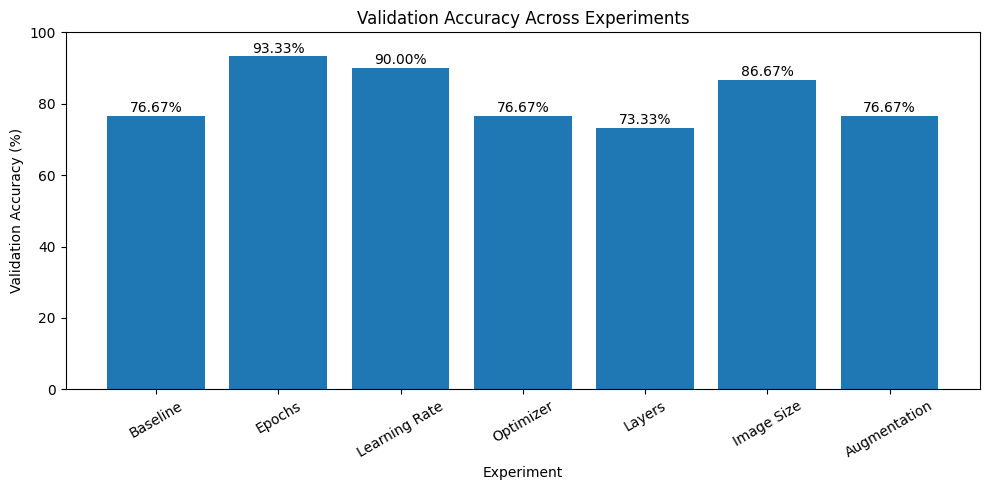

In [ ]:
# Visualize the final validation accuracy for the baseline and all experiments

experiment_names = [
    "Baseline",
    "Epochs",
    "Learning Rate",
    "Optimizer",
    "Layers",
    "Image Size",
    "Augmentation"
]

experiment_accuracies = [
    baseline_accuracy * 100,
    experiment1_accuracy * 100,
    experiment2_accuracy * 100,
    experiment3_accuracy * 100,
    experiment4_accuracy * 100,
    experiment5_accuracy * 100,
    experiment6_accuracy * 100
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    experiment_names,
    experiment_accuracies
)

plt.title("Validation Accuracy Across Experiments")
plt.xlabel("Experiment")
plt.ylabel("Validation Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)

# Add the accuracy value above each bar
for bar, accuracy in zip(bars, experiment_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Special Thanks!

Credit for the original idea and code goes to [DeepSense.ai](https://deepsense.ai/keras-vs-pytorch-avp-transfer-learning/)!
We've modified it significantly to cater to this workshop, and boost the visual appeal.

This tutorial was created through hard work and love by Jing Zhao, Dylan Wang, Jason Do, Jason Jiang, and Andrew Jong.